# 🧩 Trabajo Práctico Integrador · Entrega 5: Primer Modelo Predictivo e Interpretación Inicial

* **Institución:** Universidad Tecnológica Nacional (UTN) — Tecnicatura Universitaria en Programación a Distancia
* **Materia:** Introducción al Análisis de Datos (Unidad N° 5 · Introducción al Aprendizaje Automático)
* **Comisión:** 8
* **Integrantes del Equipo:**
  * **López, Emanuel Gustavo** (Legajo: 101135)
  * **Del Corro, Santino**
* **Número de Entrega:** Entrega N° 5 (Notebook independiente y reproducible)
* **Dataset Asignado:** `hotel booking TPI grupo H.csv` (Grupo H — 25.000 reservas)
* **Variable Objetivo:** `is_canceled` (`1` = Reserva Cancelada, `0` = Reserva No Cancelada)
* **Recorrido Elegido:** **SQL (DuckDB) + Python (`pandas`, `scikit-learn`, `matplotlib`, `seaborn`)**

---

## Introducción y Definición del Problema Predictivo

Durante la Semana 11 definimos el problema de las cancelaciones de reservas hoteleras como una tarea de **Aprendizaje Supervisado de Clasificación Binaria**:
* **Variable objetivo ($Y$):** `is_canceled`, variable discreta binaria que toma el valor `1` cuando la reserva se cancela y `0` cuando el huésped realiza el *check-in* y efectiviza su estadía.
* **Propósito:** Construir un primer modelo de árbol de decisión (`DecisionTreeClassifier`) a partir de características conocidas al momento de la reserva ($X$), generar predicciones sobre un conjunto de prueba y realizar una interpretación crítica inicial de sus resultados y limitaciones.

In [1]:
# 0. Preparación automática del entorno y carga reproducible del dataset (Local o GitHub en Colab)
import importlib.util
import subprocess
import sys
from pathlib import Path
from urllib.request import urlretrieve

for package in ["duckdb", "pandas", "scikit-learn", "matplotlib", "seaborn"]:
    module = "sklearn" if package == "scikit-learn" else package
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

GITHUB_RAW_URL = "https://raw.githubusercontent.com/Emanstor/tpi-iad-comision8/main/hotel%20booking%20TPI%20grupo%20H.csv"
POSSIBLE_PATHS = [
    Path("hotel booking TPI grupo H.csv"),
    Path("sample_data/hotel booking TPI grupo H.csv"),
    Path("hotel booking TPI grupo H (3).csv")
]

data_path = next((p for p in POSSIBLE_PATHS if p.exists()), None)
if data_path is None:
    data_path = Path("hotel booking TPI grupo H.csv")
    print("Descargando dataset original desde el repositorio GitHub del equipo...")
    urlretrieve(GITHUB_RAW_URL, data_path)

reservas_original = pd.read_csv(data_path)
con = duckdb.connect(":memory:")
con.register("reservas_original", reservas_original)
con.execute("CREATE OR REPLACE TABLE reservas AS SELECT * FROM reservas_original")

print(f"✅ Entorno preparado: {len(reservas_original):,} reservas registradas en la tabla 'reservas' de DuckDB.")

✅ Entorno preparado: 25,000 reservas registradas en la tabla 'reservas' de DuckDB.


---
## Paso 1 · Preparar los datos para el modelo (Selección SQL, Exclusiones por Fuga de Información, Faltantes y Categóricas)

### 1.1. Justificación de exclusiones para evitar Fuga de Información (*Data Leakage*) y ruido
Al construir un modelo predictivo, solo deben incluirse variables cuyo valor se conozca legítimamente antes de que ocurra el evento a predecir. Por ello, excluimos en la consulta SQL:
1. **`assigned_room_type` (Tipo de habitación asignada):** A diferencia de `reserved_room_type`, la habitación finalmente asignada suele confirmarse o modificarse operativamente en la recepción al momento del *check-in* (cuando la reserva ya no se canceló), por lo que incluirla introduciría **fuga de información (*data leakage*)**.
2. **`booking_id`:** Es un código identificador único de cada fila (`HB-024689`); no representa un atributo generalizable del cliente ni del viaje.
3. **`company` y `agent`:** Además de ser códigos identificadores de intermediarios, `company` presenta un **94,32% de valores nulos** (`23.580` faltantes sobre `25.000` filas), información que ya queda mejor representada por las variables `market_segment` y `distribution_channel`.
4. **`arrival_date` (fecha exacta de calendario):** Se excluye la fecha puntual para evitar que el árbol memorice días específicos de un año histórico, conservando el comportamiento temporal general a través de `lead_time` y la duración de la estadía.

### 1.2. Diagnóstico mediante SQL de valores faltantes y selección de variables
Verificamos mediante SQL los valores faltantes en el dataset y extraemos las variables predictoras seleccionadas:
* **Predictoras cuantitativas:** `lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children` (registra **1 valor faltante**, que se imputará en el Paso 2 usando exclusivamente la mediana de entrenamiento), `babies`, `previous_cancellations`, `booking_changes`, `adr`, `required_car_parking_spaces`, `total_of_special_requests`.
* **Predictoras categóricas a codificar:** `hotel`, `market_segment`, `deposit_type` y `customer_type`.

In [2]:
# Diagnóstico mediante SQL de valores faltantes en las columnas del dataset original
con.sql("""
SELECT
    COUNT(*) - COUNT(children) AS nulos_children,
    COUNT(*) - COUNT(country) AS nulos_country,
    COUNT(*) - COUNT(agent) AS nulos_agent,
    COUNT(*) - COUNT(company) AS nulos_company,
    COUNT(*) - COUNT(lead_time) AS nulos_lead_time,
    COUNT(*) - COUNT(adr) AS nulos_adr
FROM reservas
""").df()

,nulos_children,nulos_country,nulos_agent,nulos_company,nulos_lead_time,nulos_adr
0,1,97,3403,23580,0,0


In [3]:
# Consulta SQL para recuperar la variable objetivo (is_canceled) y los predictores seleccionados (sin variables con leakage)
df_modelo = con.sql("""
SELECT
    is_canceled,
    lead_time,
    stays_in_weekend_nights,
    stays_in_week_nights,
    adults,
    children,
    babies,
    previous_cancellations,
    booking_changes,
    adr,
    required_car_parking_spaces,
    total_of_special_requests,
    hotel,
    market_segment,
    deposit_type,
    customer_type
FROM reservas
""").df()

print(f"Datos seleccionados con SQL: {df_modelo.shape[0]:,} filas y {df_modelo.shape[1]} columnas.")
df_modelo.head()

Datos seleccionados con SQL: 25,000 filas y 16 columnas.


,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,booking_changes,adr,required_car_parking_spaces,total_of_special_requests,hotel,market_segment,deposit_type,customer_type
0,1,85,4,10,2,1.0,0,1,0,217.14,0,2,Resort Hotel,Direct,No Deposit,Group
1,1,77,0,2,2,0.0,0,0,1,79.20,0,2,City Hotel,Online TA,No Deposit,Transient
2,0,91,2,4,1,0.0,0,0,1,132.60,0,1,City Hotel,Online TA,No Deposit,Transient
3,0,0,0,1,2,0.0,0,0,0,75.00,0,2,Resort Hotel,Online TA,No Deposit,Transient
4,0,133,2,3,2,0.0,0,0,0,70.04,0,2,City Hotel,Online TA,No Deposit,Transient


---
## Paso 2 · Separar Entrenamiento y Prueba e Imputar Valores Faltantes sin Fuga de Datos

1. Dividimos el dataset de manera reproducible (`random_state=42`) y estratificada (`stratify=y`) en **Entrenamiento (70% = 17.500 reservas)** y **Prueba (30% = 7.500 reservas)**.
2. **Regla metodológica para valores faltantes:** Como la columna `children` posee un valor faltante (`NaN`), calculamos su **mediana únicamente a partir del conjunto de entrenamiento (`X_train["children"].median()`)** y utilizamos ese valor para completar tanto `X_train` como `X_test`. De esta manera evitamos que información del conjunto de prueba contamine el preprocesamiento.
3. A partir de las columnas ya limpias, calculamos las variables derivadas `total_stays_nights` y `total_guests` y transformamos las variables categóricas a formato numérico mediante *One-Hot Encoding* (`pd.get_dummies`), alineando las columnas de `X_test` con las de `X_train`.

In [4]:
# 1. Separar variable objetivo (y) y predictores (X)
y = df_modelo["is_canceled"]
X = df_modelo.drop(columns="is_canceled")

# 2. División reproducible en entrenamiento (70%) y prueba (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Completar valores faltantes en 'children' usando la mediana calculada SOLO en entrenamiento
mediana_children_train = X_train["children"].median()
X_train["children"] = X_train["children"].fillna(mediana_children_train)
X_test["children"] = X_test["children"].fillna(mediana_children_train)

# 4. Construcción de las variables derivadas (total_stays_nights y total_guests)
for subconjunto in [X_train, X_test]:
    subconjunto["total_stays_nights"] = subconjunto["stays_in_weekend_nights"] + subconjunto["stays_in_week_nights"]
    subconjunto["total_guests"] = subconjunto["adults"] + subconjunto["children"] + subconjunto["babies"]

columnas_ordenadas = [
    "lead_time", "total_stays_nights", "total_guests", "previous_cancellations",
    "booking_changes", "adr", "required_car_parking_spaces", "total_of_special_requests",
    "hotel", "market_segment", "deposit_type", "customer_type"
]
X_train = X_train[columnas_ordenadas]
X_test = X_test[columnas_ordenadas]

# 5. Codificación de variables categóricas (One-Hot Encoding) usando las categorías de entrenamiento
columnas_categoricas = ["hotel", "market_segment", "deposit_type", "customer_type"]
X_train = pd.get_dummies(X_train, columns=columnas_categoricas, drop_first=True)
X_test = pd.get_dummies(X_test, columns=columnas_categoricas, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(f"Mediana de 'children' calculada en X_train: {mediana_children_train}")
print(f"Nulos restantes en X_train: {X_train.isnull().sum().sum()} | Nulos en X_test: {X_test.isnull().sum().sum()}")
print(f"Dimensiones finales -> X_train: {X_train.shape} | X_test: {X_test.shape}")

Mediana de 'children' calculada en X_train: 0.0
Nulos restantes en X_train: 0 | Nulos en X_test: 0
Dimensiones finales -> X_train: (17500, 20) | X_test: (7500, 20)


---
## Paso 3 · Entrenar un Primer Modelo de Clasificación (Árbol de Decisión)

Entrenamos un clasificador `DecisionTreeClassifier(max_depth=3, random_state=42)` utilizando exclusivamente los datos de entrenamiento (`X_train`, `y_train`). La profundidad máxima de 3 niveles permite obtener reglas claras e interpretables.

In [5]:
# Entrenamiento del Árbol de Decisión para clasificación
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

print("✅ Árbol de decisión entrenado correctamente sobre las 17.500 reservas de entrenamiento.")

✅ Árbol de decisión entrenado correctamente sobre las 17.500 reservas de entrenamiento.


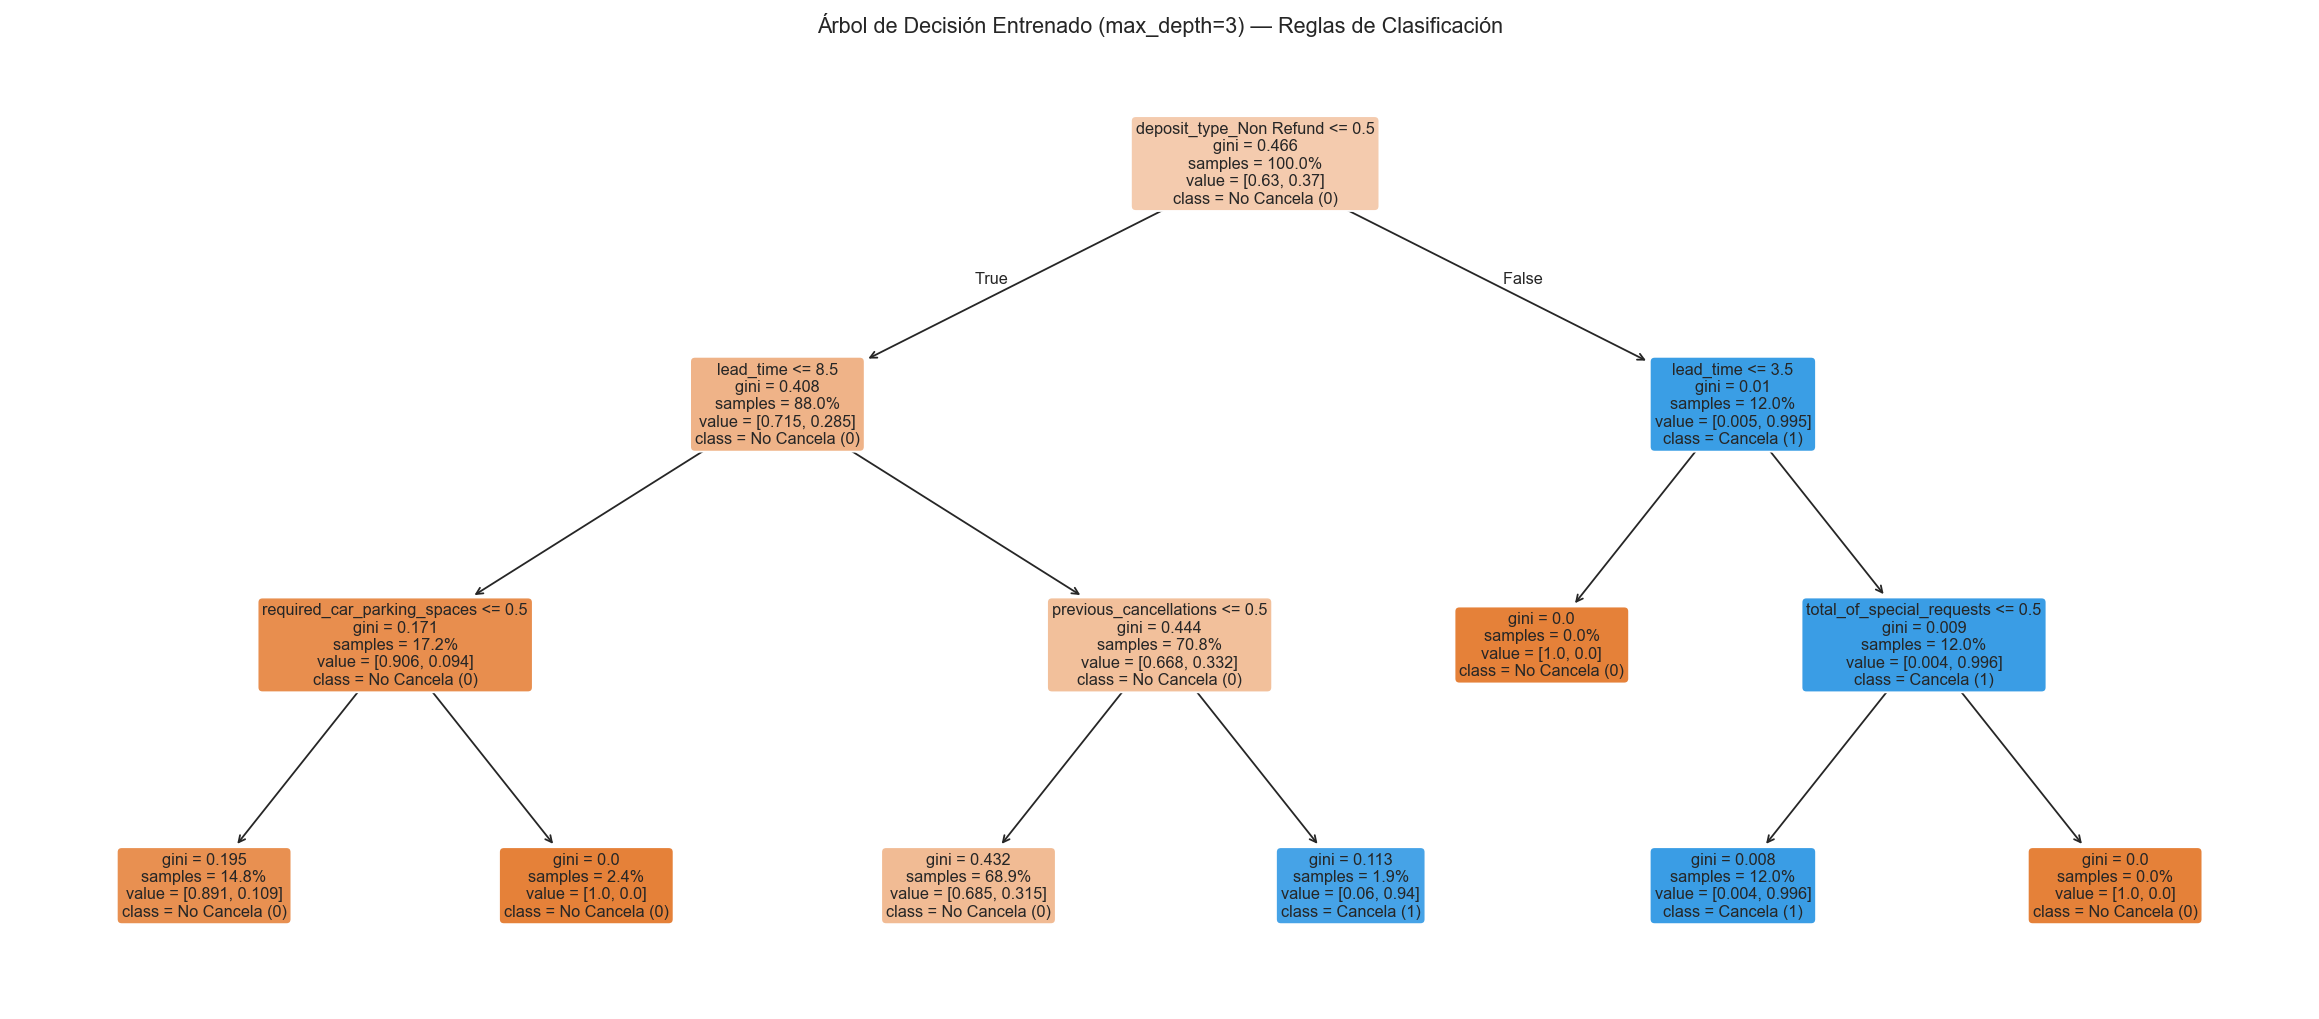

In [6]:
# Visualización de las reglas aprendidas por el Árbol de Decisión
plt.figure(figsize=(18, 8))
plot_tree(
    modelo,
    feature_names=X_train.columns,
    class_names=["No Cancela (0)", "Cancela (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    proportion=True
)
plt.title("Árbol de Decisión Entrenado (max_depth=3) — Reglas de Clasificación")
plt.tight_layout()
plt.show()

---
## Paso 4 · Generar e Inspeccionar Predicciones sobre el Conjunto de Prueba

Aplicamos el modelo entrenado sobre las `7.500` observaciones del conjunto de prueba (`X_test`) para obtener tanto la **categoría predicha (`0` o `1`)** como la **probabilidad estimada de cancelación**, y comparamos mediante **SQL** los valores predichos frente a los valores reales (`y_test`).

In [7]:
# Generación de predicciones y probabilidades sobre el conjunto de prueba (X_test)
predicciones = modelo.predict(X_test)
probabilidades = modelo.predict_proba(X_test)[:, 1]

# Armado de tabla comparativa y registro en DuckDB para inspección mediante SQL
comparacion_test = pd.DataFrame({
    "lead_time": X_test["lead_time"].to_numpy(),
    "previous_cancellations": X_test["previous_cancellations"].to_numpy(),
    "total_of_special_requests": X_test["total_of_special_requests"].to_numpy(),
    "non_refund": X_test["deposit_type_Non Refund"].astype(int).to_numpy(),
    "adr": X_test["adr"].to_numpy(),
    "valor_real": y_test.to_numpy(),
    "prediccion": predicciones,
    "prob_cancelacion": probabilidades.round(3)
})

con.register("comparacion_test", comparacion_test)

# Consulta SQL: Primeras 15 observaciones del conjunto de prueba comparando valor real vs. predicción
con.sql("""
SELECT
    lead_time,
    previous_cancellations,
    total_of_special_requests,
    non_refund,
    adr,
    valor_real,
    prediccion,
    prob_cancelacion,
    CASE
        WHEN valor_real = prediccion THEN 'Coincide (Acierto)'
        WHEN valor_real = 1 AND prediccion = 0 THEN 'No coincide (Canceló pero predijo 0)'
        ELSE 'No coincide (No canceló pero predijo 1)'
    END AS comparacion
FROM comparacion_test
LIMIT 15
""").df()

,lead_time,previous_cancellations,total_of_special_requests,non_refund,adr,valor_real,prediccion,prob_cancelacion,comparacion
0,166,0,0,1,110.00,1,1,0.996,Coincide (Acierto)
1,20,0,0,0,116.00,0,0,0.315,Coincide (Acierto)
2,56,0,3,0,222.00,0,0,0.315,Coincide (Acierto)
3,78,0,1,0,326.33,0,0,0.315,Coincide (Acierto)
4,99,0,0,0,108.00,1,0,0.315,No coincide (Canceló pero predijo 0)
5,189,0,1,0,158.00,0,0,0.315,Coincide (Acierto)
6,199,0,1,0,123.00,0,0,0.315,Coincide (Acierto)
7,277,0,2,0,96.30,0,0,0.315,Coincide (Acierto)
8,14,0,0,0,178.80,1,0,0.315,No coincide (Canceló pero predijo 0)
9,273,0,2,0,108.95,1,0,0.315,No coincide (Canceló pero predijo 0)


In [8]:
# Consulta SQL adicional: Resumen de predicciones según nivel de probabilidad estimada en el conjunto de prueba
con.sql("""
SELECT
    CASE
        WHEN prob_cancelacion < 0.25 THEN '1. Probabilidad baja (< 0.25)'
        WHEN prob_cancelacion <= 0.50 THEN '2. Probabilidad moderada / incierta (0.25 a 0.50)'
        ELSE '3. Probabilidad muy alta (> 0.50)'
    END AS nivel_riesgo_estimado,
    COUNT(*) AS cantidad_reservas_test,
    SUM(valor_real) AS cancelaciones_reales,
    ROUND(AVG(valor_real) * 100.0, 2) AS porcentaje_real_cancelado
FROM comparacion_test
GROUP BY nivel_riesgo_estimado
ORDER BY nivel_riesgo_estimado
""").df()

,nivel_riesgo_estimado,cantidad_reservas_test,cancelaciones_reales,porcentaje_real_cancelado
0,1. Probabilidad baja (< 0.25),1366,133.0,9.74
1,2. Probabilidad moderada / incierta (0.25 a 0.50),5045,1568.0,31.08
2,3. Probabilidad muy alta (> 0.50),1089,1077.0,98.90


---
## Paso 5 · Interpretación de los Resultados, Utilidad y Limitaciones (Cierre de la Entrega 5)

### 5.1. ¿Qué observamos en las primeras predicciones del conjunto de prueba?
1. **Aciertos claros en los extremos:** En reservas de corta anticipación (`lead_time <= 8` días) sin antecedentes, el modelo estima una probabilidad de cancelación muy baja (`~0.095`) y predice `0 (No Cancela)`, coincidiendo en la gran mayoría de los casos con el valor real. En el otro extremo, cuando detecta reservas con depósito `Non Refund` o con historial de cancelaciones previas (`previous_cancellations >= 1`) y anticipación mayor a 17 días, asigna probabilidades superiores a `0.85 - 0.99` y predice `1 (Cancela)` con altísima efectividad.
2. **Desacuerdos observados (cuando el valor real es `1` y la predicción es `0`):** En las primeras 15 filas se observan casos donde el cliente realmente canceló (`valor_real = 1`), pero el modelo predijo `0 (No Cancela)` con una probabilidad intermedia de **`0.369` (36,9%)**. Esto ocurre porque el árbol agrupa allí a las reservas sin depósito previo con más de 8 días de anticipación: como el 36,9% es menor al umbral de corte por defecto (`0.50`), el clasificador etiqueta a todo el grupo como `0`, aunque más de un tercio de esas reservas termine cancelándose.

### 5.2. ¿Qué utilidad práctica podrían tener estas predicciones para el hotel?
* **Sistema de alerta temprana y segmentación de gestión:** Permite al equipo de reservas identificar automáticamente desde el momento de la compra cuáles reservas tienen una probabilidad casi segura de caída (`> 85%`) y cuáles tienen un riesgo intermedio (`~37%`), para aplicar acciones diferenciadas (como solicitar reconfirmación activa de estadía, ofrecer incentivos por pago anticipado o ajustar los cupos de disponibilidad por canal).

### 5.3. Limitaciones que deben considerarse antes de tomar decisiones (al menos dos aspectos)
1. **Pérdida de información al usar únicamente la etiqueta binaria (`0/1`) en casos de incertidumbre media:**
   * Clasificar como "segura (`0`)" una reserva que tiene un **36,9% de probabilidad de cancelación** puede inducir a un exceso de confianza operativa. Antes de tomar decisiones comerciales, conviene utilizar la **probabilidad continua estimada** y evaluar formalmente cuántos falsos negativos y falsos positivos produce el modelo (análisis que se desarrolla en la **Entrega 6**).
2. **Riesgo de sesgo administrativo en `deposit_type` (*Non Refund*) y ausencia de relaciones causales:**
   * El árbol apoya su primera partición en `deposit_type_Non Refund`. Debe validarse que dicho campo no refleje una marca contable posterior al incumplimiento del huésped. Además, el modelo captura **correlaciones históricas y no causas directas**, y no observa factores externos (clima, eventos, precios de competidores), por lo que sus salidas deben complementar —y nunca reemplazar automáticamente— el criterio de negocio.

In [9]:
con.close()
print("🔒 Conexión a DuckDB cerrada correctamente. Notebook de la Entrega 5 ejecutado de principio a fin.")

🔒 Conexión a DuckDB cerrada correctamente. Notebook de la Entrega 5 ejecutado de principio a fin.
